# From thousands of Kenyon cells to one: synapses and mitochondria in the hemibrain connectome

In this notebook you will **zoom in step by step** on the *Drosophila* mushroom body, and look at the neurons inside the brain at every step:

| Level | Neurons |
|---|---|
| 1 | All Kenyon cells (KCs) |
| 2 | All γ-KCs |
| 3 | γ-main KCs (`KCg-m`, the main γ subtype) |
| 4 | A single γ-main KC |

At each level we count **synapses** and **mitochondria**. Then we study the single γ-KC in detail: its partners, its skeleton, where its synapses and mitochondria are, how far synapses are from mitochondria, how large its mitochondria are, and how all of this differs between the **γ1–γ5 compartments** of the γ lobe.

**Data:** FlyEM hemibrain v1.2.1 — most of the right half of an adult female *Drosophila* central brain, imaged by electron microscopy at 8 nm resolution (Scheffer *et al.* 2020; mitochondria: Longden *et al.* 2024).

**How to use it:** run the cells in order with **Shift + Enter**. Every code cell starts with a number such as `# [12]`, so we can refer to it in class and in the exercises. Cells marked **✏️** contain a value you can change. Tables can be saved as **CSV files** (they appear in the Files panel on the left in Colab, from where you can download them).

### Units used by neuPrint
| What | Unit in the data | We convert with |
|---|---|---|
| Positions (`x, y, z`) and skeletons | voxels (1 voxel = 8 nm) | × 0.008 → µm |
| Neuron and mitochondrion `size` | number of voxels | × 0.000000512 → µm³ |
| Synapse-to-mitochondrion `distance` | voxels, measured **inside the neuron** (not a straight line) | × 0.008 → µm |

## 0. Setup
The first cell installs `neuprint-python` if it is missing (needed on Google Colab). The second loads the packages we use.

In [ ]:
# [1]
# Check which packages are missing and install only those (takes ~30 s the first time on Colab)
import importlib.util, subprocess, sys

needed = {"neuprint": "neuprint-python", "plotly": "plotly"}        # {name to import: name to install}
missing = [pkg for mod, pkg in needed.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("Packages ready.")

Packages ready.


In [ ]:
# [2]
# Standard data-science packages
import re
import numpy as np                    # numbers and arrays
import pandas as pd                   # tables (DataFrames)
import matplotlib.pyplot as plt       # 2D plots
import plotly.graph_objects as go     # interactive 3D plots

# neuprint-python: the functions that send queries to the neuPrint server
from neuprint import (Client,                               # the connection to the server
                      NeuronCriteria as NC,                 # "which neurons?"
                      SynapseCriteria as SC,                # "which synapses?"
                      MitoCriteria as MC,                   # "which mitochondria?"
                      fetch_primary_rois, fetch_roi_hierarchy,
                      fetch_neurons, fetch_adjacencies, merge_neuron_properties,
                      fetch_synapses, fetch_mitochondria, fetch_synapses_and_closest_mitochondria,
                      fetch_skeleton)

pd.set_option("display.max_columns", 30)      # show more columns when printing tables
VOXEL_UM = 0.008                              # 1 voxel = 8 nm = 0.008 µm
VOXEL_UM3 = VOXEL_UM ** 3                     # volume of 1 voxel in µm³

### Connect to neuPrint
You need your personal token (neuprint.janelia.org → account menu, top right → **Account** → copy the token).
* **Colab:** key icon in the left sidebar → add a secret called `NEUPRINT_TOKEN` → allow notebook access.
* Otherwise you will be asked to paste it below. Never save the token inside the notebook.

In [ ]:
# [3]
import os, getpass

# 1) Look for the token in an environment variable (JupyterHub / your own computer)
TOKEN = os.environ.get("NEUPRINT_APPLICATION_CREDENTIALS")
# 2) ...otherwise in a Colab secret called NEUPRINT_TOKEN
if not TOKEN:
    try:
        from google.colab import userdata
        TOKEN = userdata.get("NEUPRINT_TOKEN")
    except Exception:
        pass
# 3) ...otherwise ask for it (the text you paste is hidden)
if not TOKEN:
    TOKEN = getpass.getpass("Paste your neuPrint token: ")

# Create the connection. Every query below uses this client automatically.
c = Client("neuprint.janelia.org", "hemibrain:v1.2.1", TOKEN)
print("Connected:", c.dataset)

Paste your neuPrint token: ··········
Connected: hemibrain:v1.2.1


### Helper functions (just run this cell)
This cell defines small functions for drawing. You do not need to read it, but here is what they do:
* `draw_hemibrain(ax)` — draws the **whole hemibrain** in light grey as a background, so you always know where you are.
* `draw_neuropil(ax, rois)` — shades one or more brain regions (ROI meshes) behind the data.
* `draw_neurons(ax, neurons)` — draws neuron **skeletons**, coloured by cell type.
* Every 2D plot is a **frontal view**, looking from anterior to posterior: dorsal up, and the fly's right on *your* left (as in neuPrint and Virtual Fly Brain). Because neuPrint's x, y, z are microscope axes, `body_axes()` works out which axis is dorsal, anterior and lateral from the shapes of known neuropils.

In [ ]:
# [4]
from matplotlib.collections import PolyCollection

# ---- colours used in every plot -------------------------------------------------------
PRE_COL, POST_COL, MITO_COL = "#E66100", "#1F5FBF", "#E7298A"                      # orange, blue, pink
MITO_CLASS_COL = {"dark": "#9C1458", "medium": "#E7298A", "light": "#F7A8CF"}       # pink shades
ROI_COL, MB_COL, BRAIN_COL = "#F2A65A", "#B9A6D6", "#9E9E9E"                        # chosen ROI, MB, brain
KC_CLASS_COL = {"KCg": "#E07A2E", "KCa'b'": "#2A9D8F", "KCab": "#7B5EA7"}           # γ, α′/β′, α/β KCs


# ---- ROI meshes -----------------------------------------------------------------------
_MESHES = {}


def roi_mesh(roi):
    # Download an ROI mesh (.obj file) once and keep it: vertices (N x 3, voxels) and triangles (M x 3)
    if roi not in _MESHES:
        verts, faces = [], []
        for line in c.fetch_roi_mesh(roi).decode().splitlines():
            parts = line.split()
            if parts and parts[0] == "v":                       # a vertex: v x y z
                verts.append([float(v) for v in parts[1:4]])
            elif parts and parts[0] == "f":                     # a triangle: f i j k
                faces.append([int(q.split("/")[0]) - 1 for q in parts[1:4]])
        _MESHES[roi] = (np.array(verts), np.array(faces))
    return _MESHES[roi]


# ---- frontal view ---------------------------------------------------------------------
_AXES = {}


def body_axes():
    # neuPrint x, y, z are microscope axes, and datasets differ (hemibrain: z = dorsal-ventral;
    # male CNS: y = dorsal-ventral). So we find the body axes from neuropils we know:
    #   the alpha lobe is long dorso-ventrally and lies dorsal of the beta lobe,
    #   the beta lobe is long medio-laterally,
    #   the antennal lobe is anterior of the calyx, and the calyx is right of the midline (EB).
    if not _AXES:
        cen = lambda r: roi_mesh(r)[0].mean(axis=0)
        ext = lambda r: np.ptp(roi_mesh(r)[0], axis=0)
        def unit(i, sign):
            u = np.zeros(3); u[i] = 1.0 if sign >= 0 else -1.0
            return u
        dv = int(np.argmax(ext("aL(R)")))
        rest = [i for i in range(3) if i != dv]
        lat = max(rest, key=lambda i: ext("bL(R)")[i])
        ap = [i for i in rest if i != lat][0]
        _AXES.update(D=unit(dv, cen("aL(R)")[dv] - cen("bL(R)")[dv]),     # dorsal
                     A=unit(ap, cen("AL(R)")[ap] - cen("CA(R)")[ap]),     # anterior
                     R=unit(lat, cen("CA(R)")[lat] - cen("EB")[lat]))     # fly's right
    return _AXES


def to_front(P):
    # Points (N x 3, voxels) -> horizontal, vertical coordinates in µm, looking from anterior to posterior:
    # dorsal up, and the fly's right on YOUR left (as when you face the fly)
    o = body_axes()
    P = np.asarray(P, dtype=float) * VOXEL_UM
    return P @ -o["R"], P @ o["D"]


def front_df(df):
    # Same for a table with x, y, z columns (synapses, mitochondria)
    return to_front(df[["x", "y", "z"]].values)


def skeleton_lines(sk):
    # Turn a skeleton table into x, y, z arrays (µm) that draw every branch (segments separated by NaN)
    seg = sk.merge(sk, left_on="link", right_on="rowId", suffixes=("", "_p"))
    return {k: np.c_[seg[k], seg[k + "_p"], np.full(len(seg), np.nan)].ravel() * VOXEL_UM for k in "xyz"}


def front_lines(lines):
    return to_front(np.c_[lines["x"], lines["y"], lines["z"]] / VOXEL_UM)


def label_front(ax):
    ax.autoscale_view(); ax.set_aspect("equal")
    ax.set_xlabel("fly's left → (µm)"); ax.set_ylabel("dorsal ↑ (µm)")


# ---- drawing --------------------------------------------------------------------------
def draw_mesh(ax, roi, colour, alpha, label=None):
    v, f = roi_mesh(roi)
    h, vv = to_front(v)
    ax.add_collection(PolyCollection(np.stack([h[f], vv[f]], axis=-1), facecolor=colour, edgecolor="none",
                                     alpha=alpha, zorder=0, rasterized=True))
    if label:
        ax.plot([], [], c=colour, lw=8, alpha=0.6, label=label)       # legend entry


def draw_hemibrain(ax):
    # Whole hemibrain in light grey. Uses the 'hemibrain' mesh if the server has one,
    # otherwise all primary ROIs together (they tile the brain).
    try:
        draw_mesh(ax, "hemibrain", BRAIN_COL, 0.02, "hemibrain")
    except Exception:
        for i, roi in enumerate(primary):
            draw_mesh(ax, roi, BRAIN_COL, 0.015, "hemibrain" if i == 0 else None)
    ax.autoscale_view()


def draw_neuropil(ax, rois=None):
    # Shade regions: rois = {name: (colour, transparency)}. Default: whole MB + your ROI_OF_INTEREST
    rois = rois or {"MB(R)": (MB_COL, 0.04), ROI_OF_INTEREST: (ROI_COL, 0.15)}
    for roi, (colour, alpha) in rois.items():
        draw_mesh(ax, roi, colour, alpha, roi)
    ax.autoscale_view()


_SKELETONS = {}


def get_skeleton(body):
    # Download a skeleton once (heal=True joins fragments into one tree)
    if body not in _SKELETONS:
        _SKELETONS[body] = fetch_skeleton(int(body), heal=True)
    return _SKELETONS[body]


def type_colour(t):
    for prefix, col in sorted(KC_CLASS_COL.items(), key=lambda kv: -len(kv[0])):   # longest prefix first
        if str(t).startswith(prefix):
            return col
    return "dimgrey"


CLASS_CMAP = {"KCg": "Oranges", "KCa'b'": "BuGn", "KCab": "Purples"}


def subtype_colours(types):
    # One shade per subtype, within its class colour (e.g. KCg-m, KCg-d ... in different oranges)
    out, types = {}, sorted(types)
    for prefix in sorted(CLASS_CMAP, key=len, reverse=True):
        members = [t for t in types if str(t).startswith(prefix) and t not in out]
        cmap = plt.get_cmap(CLASS_CMAP[prefix])
        for i, t in enumerate(members):
            out[t] = cmap(0.85 - 0.45 * i / max(len(members) - 1, 1))
    return {t: out.get(t, "dimgrey") for t in types}


def draw_neurons(ax, neurons, lw=0.5):
    # Draw the skeleton of every neuron in a table (needs columns bodyId and type), one shade per subtype
    cols = subtype_colours(neurons["type"].unique())
    for body, t in zip(neurons["bodyId"], neurons["type"]):
        ax.plot(*front_lines(skeleton_lines(get_skeleton(body))), c=cols[t], lw=lw, zorder=2)
    for t, col in cols.items():
        ax.plot([], [], c=col, lw=2, label=t)


def plot_level(neurons, title, n_show=30, seed=0):
    # One zoom level: hemibrain (grey) + MB and your ROI (shaded) + a random sample of skeletons
    show = neurons.sample(min(n_show, len(neurons)), random_state=seed)
    fig, ax = plt.subplots(figsize=(11, 8))
    draw_hemibrain(ax)
    draw_neuropil(ax)
    draw_neurons(ax, show, lw=0.5 if len(show) > 1 else 1.0)
    label_front(ax)
    ax.set_title(f"{title}: {len(show)} of {len(neurons)} neurons drawn (frontal view)")
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False, fontsize=9)
    plt.show()


def camera():
    # Plotly 3D camera: start in frontal view (eye in front of the fly looking back, dorsal up)
    o = body_axes()
    return dict(eye=dict(zip("xyz", o["A"] * 2)), up=dict(zip("xyz", o["D"])))


def neuropil_3d(rois=None, opacity=0.08):
    # Plotly 3D meshes for regions (default: whole MB + your ROI_OF_INTEREST)
    rois = rois or {"MB(R)": (MB_COL, 0), ROI_OF_INTEREST: (ROI_COL, 0)}
    traces = []
    for roi, (colour, _) in rois.items():
        v, f = roi_mesh(roi)
        traces.append(go.Mesh3d(x=v[:, 0] * VOXEL_UM, y=v[:, 1] * VOXEL_UM, z=v[:, 2] * VOXEL_UM,
                                i=f[:, 0], j=f[:, 1], k=f[:, 2], color=colour, opacity=opacity,
                                name=roi, showlegend=True, hoverinfo="name"))
    return traces


# ---- saving tables ---------------------------------------------------------------------
def save_csv(df, filename):
    # Save a table as a CSV file (opens in Excel / Google Sheets). In Colab: Files panel -> right-click -> Download
    df.to_csv(filename)
    print(f"saved {filename}  ({len(df)} rows)")


print("Helpers ready.")

Helpers ready.


## 1. Brain regions (ROIs) — choose the one you want to look at
neuPrint divides the brain into named **regions of interest (ROIs)**. Names ending in `(R)` or `(L)` are on the fly's right or left side.
* **Primary ROIs** do not overlap and together tile the brain (e.g. `CA(R)` calyx, `PED(R)` pedunculus, `gL(R)` γ lobe).
* Some primary ROIs contain **sub-regions**, e.g. the γ lobe `gL(R)` contains its five compartments `g1(R)` … `g5(R)`.

Run the next cell to see them all.

In [ ]:
# [5]
# Step 1: the primary ROIs (non-overlapping regions that tile the brain)
primary = fetch_primary_rois()
print(len(primary), "primary ROIs:\n")
print(", ".join(primary))

# Step 2: the full hierarchy - which regions are inside which (primary ones are marked *)
print("\nROI hierarchy:\n")
print(fetch_roi_hierarchy(False, mark_primary=True, format="text"))

63 primary ROIs:

AB(L), AB(R), AL(L), AL(R), AME(R), AOTU(R), ATL(L), ATL(R), AVLP(R), BU(L), BU(R), CA(L), CA(R), CAN(R), CRE(L), CRE(R), EB, EPA(L), EPA(R), FB, FLA(R), GNG, GOR(L), GOR(R), IB, ICL(L), ICL(R), IPS(R), LAL(L), LAL(R), LH(R), LO(R), LOP(R), ME(R), NO, PB, PED(R), PLP(R), PRW, PVLP(R), SAD, SCL(L), SCL(R), SIP(L), SIP(R), SLP(R), SMP(L), SMP(R), SPS(L), SPS(R), VES(L), VES(R), WED(R), a'L(L), a'L(R), aL(L), aL(R), b'L(L), b'L(R), bL(L), bL(R), gL(L), gL(R)

ROI hierarchy:

hemibrain
 +-- AL(L)*
 +-- AL(R)*
 +-- AOT(R)
 +-- CX
 |   +-- AB(L)*
 |   +-- AB(R)*
 |   +-- EB*
 |   +-- FB*
 |   +-- NO*
 |   +-- PB*
 +-- GC
 +-- GF(R)
 +-- GNG*
 +-- INP
 |   +-- ATL(L)*
 |   +-- ATL(R)*
 |   +-- CRE(L)*
 |   +-- CRE(R)*
 |   +-- IB*
 |   +-- ICL(L)*
 |   +-- ICL(R)*
 |   +-- SCL(L)*
 |   +-- SCL(R)*
 +-- LH(R)*
 +-- LX(L)
 |   +-- BU(L)*
 |   +-- LAL(L)*
 +-- LX(R)
 |   +-- BU(R)*
 |   +-- LAL(R)*
 +-- MB(+ACA)(R)
 |   +-- MB(R)
 |   |   +-- CA(R)*
 |   |   +-- PED(R)*
 |   | 

### ✏️ Type the ROI you are interested in
Copy a name **exactly** as printed above (names are case-sensitive, including the brackets). This region will be **highlighted in orange in every anatomical plot** of the notebook, and counted separately in the tables.

Start with `gL(R)` (the γ lobe). Later, try `CA(R)` (calyx), `PED(R)` (pedunculus), `g1(R)` (γ1 compartment) or a region outside the mushroom body, then re-run the notebook.

In [ ]:
# [6]
ROI_OF_INTEREST = "gL(R)"          # ✏️ CHANGE ME, e.g. "CA(R)", "g1(R)", "aL(R)"

# Check the name exists; if not, suggest the closest names
if ROI_OF_INTEREST not in c.all_rois:
    import difflib
    print(f"'{ROI_OF_INTEREST}' is not an ROI in {c.dataset}. Did you mean:",
          difflib.get_close_matches(ROI_OF_INTEREST, c.all_rois, n=5, cutoff=0.3))
else:
    print("ROI_OF_INTEREST =", ROI_OF_INTEREST, "| primary ROI:", ROI_OF_INTEREST in primary)

# Which microscope axis is which body axis? (used for the frontal view)
name = lambda u: ("+" if u.max() > 0 else "−") + "xyz"[int(np.argmax(np.abs(u)))]
print("body axes:", {k: name(v) for k, v in {"dorsal": body_axes()["D"], "anterior": body_axes()["A"],
                                            "fly's right": body_axes()["R"]}.items()})

ROI_OF_INTEREST = gL(R) | primary ROI: True
body axes: {'dorsal': '−z', 'anterior': '+y', "fly's right": '−x'}


Where is your ROI in the brain? Grey = whole hemibrain, purple = whole mushroom body, orange = your ROI.

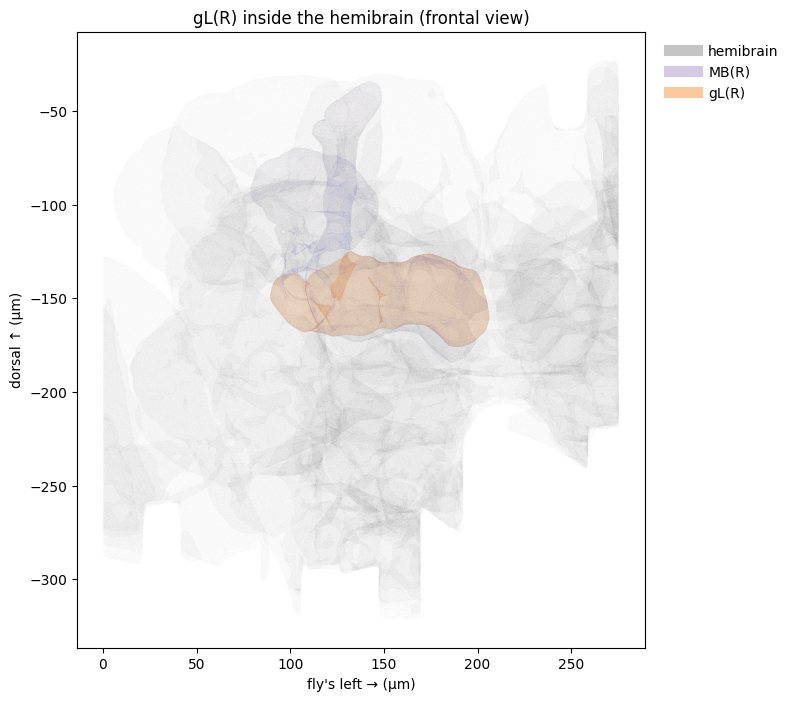

In [ ]:
# [7]
fig, ax = plt.subplots(figsize=(11, 8))
draw_hemibrain(ax)          # background: whole hemibrain
draw_neuropil(ax)           # mushroom body + ROI_OF_INTEREST
label_front(ax)
ax.set_title(f"{ROI_OF_INTEREST} inside the hemibrain (frontal view)")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)
plt.show()

### Regions used for the compartment analysis
For a γ-KC we follow the neuron from the calyx (`CA(R)`, where it receives input) through the pedunculus (`PED(R)`) into the γ-lobe compartments `g1(R)` … `g5(R)` (where it makes most outputs).

In [ ]:
# [8]
# Find the γ-lobe compartments automatically: names like g1(R), g2(R), ...
GAMMA_COMPS = sorted(r for r in c.all_rois if re.fullmatch(r"g\d\(R\)", r))
REGIONS = ["CA(R)", "PED(R)"] + GAMMA_COMPS          # the regions a γ-KC passes through, in order
print("Compartment regions:", REGIONS)

Compartment regions: ['CA(R)', 'PED(R)', 'g1(R)', 'g2(R)', 'g3(R)', 'g4(R)', 'g5(R)']


### Three more small helpers (just run)
`label_regions` and `label_synapses` tag every synapse / mitochondrion with its compartment; `mito_per_neuron` counts mitochondria per neuron.

In [ ]:
# [9]
def label_regions(df, key_cols):
    # neuPrint lists a synapse/mitochondrion once for EVERY region it lies in (g1(R), gL(R), MB(R) ...).
    # Keep one row per point, add 'region' (from REGIONS, or 'other') and 'in_ROI' (inside ROI_OF_INTEREST?).
    first = df.drop_duplicates(key_cols).drop(columns="roi")
    reg = (df[df["roi"].isin(REGIONS)].drop_duplicates(key_cols)[key_cols + ["roi"]]
           .rename(columns={"roi": "region"}))
    out = first.merge(reg, on=key_cols, how="left")
    out["region"] = out["region"].fillna("other")
    in_roi = df[df["roi"] == ROI_OF_INTEREST].drop_duplicates(key_cols)[key_cols].assign(in_ROI=True)
    out = out.merge(in_roi, on=key_cols, how="left")
    out["in_ROI"] = out["in_ROI"].fillna(False).astype(bool)
    return out


def label_synapses(body_id):
    # Synapses of one neuron, one row each, with 'region' (from REGIONS or 'other') and 'in_ROI'.
    # NOTE: with primary_only=False, neuprint-python (0.6.4) keeps only ONE of the regions a synapse lies in,
    # so the 'roi' column cannot be trusted for sub-regions. Instead we ask neuPrint once per region.
    keys = ["type", "x", "y", "z"]
    syn = fetch_synapses(body_id, SC(primary_only=True)).drop_duplicates(keys).reset_index(drop=True)
    idx = syn.set_index(keys).index

    def inside(roi):                      # True for every synapse that lies in this region
        found = fetch_synapses(body_id, SC(rois=[roi], primary_only=False))
        return idx.isin(found.set_index(keys).index)

    syn["region"] = "other"
    for reg in REGIONS:
        syn.loc[inside(reg), "region"] = reg
    syn["in_ROI"] = inside(ROI_OF_INTEREST)
    return syn


def mito_per_neuron(roi_df):
    # Mitochondria per neuron = sum over primary regions (they do not overlap, so nothing is counted twice)
    return roi_df[roi_df["roi"].isin(primary)].groupby("bodyId")["mito"].sum()

---
## 2. Zooming in: all KCs → γ-KCs → γ-main KCs → one γ-KC

`fetch_neurons` returns **two tables**:
* **neurons** — one row per neuron: `type`, `pre` (presynaptic sites), `post` (postsynaptic sites), `size` (volume in voxels), `status`, `cropped` …
* **roi_counts** — one row per neuron *per brain region*: synapses (`pre`, `post`) and mitochondria (`mito`) in that region.

We query neuPrint **once** for all KCs, then narrow down with pandas filtering — no new queries needed.

### Level 1 — all Kenyon cells
`type="KC.*"` is a *pattern*: `.*` means "anything", so it matches every type starting with `KC`.

In [ ]:
# [10]
# Step 1: ask neuPrint for every neuron whose type starts with "KC"
all_kc, all_kc_roi = fetch_neurons(NC(type="KC.*"))

# Step 2: how many, and of which types?
print(len(all_kc), "Kenyon cells\n")
all_kc["type"].value_counts()

1927 Kenyon cells



,count
type,
KCg-m,590
KCab-m,354
KCab-c,252
KCab-s,223
KCa'b'-ap2,127
KCa'b'-m,119
KCg-d,99
KCa'b'-ap1,91
KCab-p,60


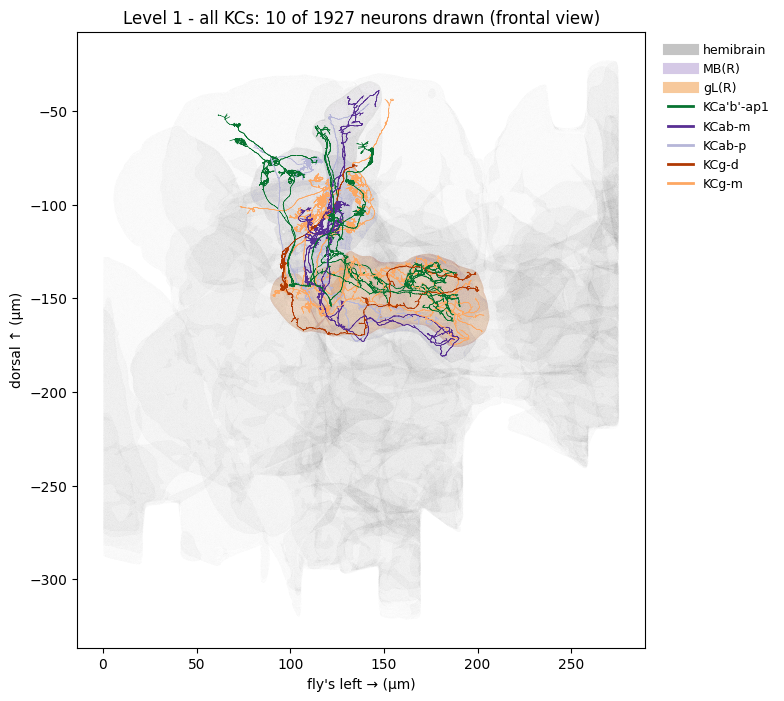

In [ ]:
# [11]
# Step 3: draw a random sample of 30 KCs inside the brain.
# Colours: oranges = γ KCs, greens = α′/β′ KCs, purples = α/β KCs (one shade per subtype).
# Downloading 30 skeletons takes a few seconds; change n_show to draw more or fewer.
plot_level(all_kc, "Level 1 - all KCs", n_show=10)

### Level 2 — γ-KCs only
We keep only rows whose `type` starts with `KCg`. `.str.startswith()` tests the beginning of each text value. (No plot here: we go straight on to the γ-main KCs.)

In [ ]:
# [12]
# Step 1: filter the neuron table
g_kc = all_kc[all_kc["type"].str.startswith("KCg")]
# Step 2: keep the matching rows of the region table (same bodyIds)
g_kc_roi = all_kc_roi[all_kc_roi["bodyId"].isin(g_kc["bodyId"])]

print(len(g_kc), "γ-KCs:", g_kc["type"].value_counts().to_dict())

701 γ-KCs: {'KCg-m': 590, 'KCg-d': 99, 'KCg-t': 8, 'KCg-s4': 1, 'KCg-s1': 1, 'KCg-s3': 1, 'KCg-s2': 1}


### Level 3 — γ-main KCs (`KCg-m`)
The γ lobe contains several KC subtypes; `KCg-m` ("main") is by far the largest group.

In [ ]:
# [13]
# Step 1: keep only the main γ subtype (exact match this time)
gm_kc = g_kc[g_kc["type"] == "KCg-m"]
gm_kc_roi = g_kc_roi[g_kc_roi["bodyId"].isin(gm_kc["bodyId"])]

print(len(gm_kc), "γ-main KCs")
plot_level(gm_kc, "Level 3 - γ-main KCs")

### Level 4 — one γ-main KC
We pick a *typical* KCg-m:
* `status == "Traced"` — fully reconstructed;
* not `cropped` — not cut off at the edge of the imaged volume;
* the **median** number of synapses among those.

In [ ]:
# [14]
# Step 1: keep complete neurons only
candidates = gm_kc[(gm_kc["status"] == "Traced") & (gm_kc["cropped"] != True)].copy()

# Step 2: sort them by total synapses and take the one in the middle (the median)
candidates["n_syn"] = candidates["pre"] + candidates["post"]
candidates = candidates.sort_values("n_syn")
KC_ID = int(candidates["bodyId"].iloc[len(candidates) // 2])

# Step 3: its two tables
one_kc = gm_kc[gm_kc["bodyId"] == KC_ID]
one_kc_roi = gm_kc_roi[gm_kc_roi["bodyId"] == KC_ID]
print("Our γ-KC:", KC_ID)
one_kc[["bodyId", "type", "instance", "pre", "post", "size", "status", "cropped"]]

### Optional: use a neuron you chose yourself
Found an interesting neuron in neuPrint Explorer (neuprint.janelia.org)? Paste its **bodyId** below and run the cell. Everything after this point (the summary table and Part 3) will use your neuron instead. Leave `MY_BODY_ID = None` to keep the automatically chosen γ-KC.

*Tip:* the compartment analysis is built for γ-KCs (calyx, pedunculus, γ1–γ5). For other neurons most points will be labelled `other`; change `REGIONS` and `ROI_OF_INTEREST` to suit your neuron.

In [ ]:
# [15]
MY_BODY_ID = None          # ✏️ e.g. MY_BODY_ID = 1234567890

if MY_BODY_ID is not None:
    my_neuron, my_roi = fetch_neurons(int(MY_BODY_ID))        # ask neuPrint for this one neuron
    if my_neuron.empty:
        print(f"bodyId {MY_BODY_ID} not found in {c.dataset} - keeping KC {KC_ID}")
    else:
        KC_ID, one_kc, one_kc_roi = int(MY_BODY_ID), my_neuron, my_roi
        info = my_neuron.iloc[0]
        print(f"Using your neuron {KC_ID}: type={info['type']}, status={info['status']}, cropped={info['cropped']}")
        if not str(info["type"]).startswith("KCg"):
            print("Note: this is not a γ-KC, so the γ1–γ5 compartment results will mostly be 'other'.")
else:
    print("No bodyId given - using the automatically chosen γ-KC", KC_ID)

In [ ]:
# [16]
# Draw the single neuron inside the brain
plot_level(one_kc, f"Level 4 - one γ-KC ({KC_ID})")

### Summary table: synapses and mitochondria at each level
For each level we add up the columns of the two tables. The last three columns count only what lies inside your `ROI_OF_INTEREST`.

In [ ]:
# [17]
# The four levels, each as (neuron table, region table)
levels = {
    "1. All KCs":     (all_kc, all_kc_roi),
    "2. γ-KCs":       (g_kc, g_kc_roi),
    "3. γ-main KCs":  (gm_kc, gm_kc_roi),
    "4. One γ-KC":    (one_kc, one_kc_roi),
}

rows = {}
for name, (neurons, roi_counts) in levels.items():
    mito = mito_per_neuron(roi_counts).reindex(neurons["bodyId"]).fillna(0)   # mitochondria per neuron
    volume = neurons["size"].sum() * VOXEL_UM3                                # total volume in µm³
    in_roi = roi_counts[roi_counts["roi"] == ROI_OF_INTEREST]                 # rows for your ROI only
    rows[name] = {
        "neurons":                   len(neurons),
        "presynapses":               neurons["pre"].sum(),
        "postsynapses":              neurons["post"].sum(),
        "mitochondria":              mito.sum(),
        "volume (µm³)":              volume,
        "presynapses / neuron":      neurons["pre"].mean(),
        "postsynapses / neuron":     neurons["post"].mean(),
        "mitochondria / neuron":     mito.mean(),
        "mitochondria / 100 µm³":    100 * mito.sum() / volume,
        "mitochondria / presynapse": mito.sum() / neurons["pre"].sum(),
        f"pre in {ROI_OF_INTEREST}":  in_roi["pre"].sum(),
        f"post in {ROI_OF_INTEREST}": in_roi["post"].sum(),
        f"mito in {ROI_OF_INTEREST}": in_roi["mito"].sum(),
    }
level_summary = pd.DataFrame(rows).T
save_csv(level_summary.round(3), "level_summary.csv")        # export the table
level_summary.round(2)

The same numbers per KC **class**: γ (`KCg…`), α/β (`KCab…`) and α′/β′ (`KCa'b'…`). We first give every KC a `class` from the start of its type name, then average per class with `groupby`.

In [ ]:
# [18]
# Step 1: add mitochondria and volume (µm³) as new columns
all_kc["mito"] = all_kc["bodyId"].map(mito_per_neuron(all_kc_roi)).fillna(0)
all_kc["volume_um3"] = all_kc["size"] * VOXEL_UM3

# Step 2: give every KC its class from the start of the type name (check the longest prefix first)
def kc_class(t):
    if t.startswith("KCa'b'"):
        return "α′/β′ (KCa'b')"
    if t.startswith("KCab"):
        return "α/β (KCab)"
    if t.startswith("KCg"):
        return "γ (KCg)"
    return "other"

all_kc["class"] = all_kc["type"].map(kc_class)

# Step 3: average per class
by_class = all_kc.groupby("class").agg(neurons=("bodyId", "size"),
                                       pre_per_neuron=("pre", "mean"),
                                       post_per_neuron=("post", "mean"),
                                       mito_per_neuron=("mito", "mean"),
                                       volume_um3=("volume_um3", "mean"))
by_class = by_class.loc[[c_ for c_ in ["γ (KCg)", "α/β (KCab)", "α′/β′ (KCa'b')"] if c_ in by_class.index]]
save_csv(by_class.round(3), "kc_by_class.csv")               # export the table
by_class.round(1)

In [ ]:
# [19]
# One bar chart per column, one bar per KC class (orange = γ, purple = α/β, green = α′/β′)
CLASS_COL = {"γ (KCg)": KC_CLASS_COL["KCg"], "α/β (KCab)": KC_CLASS_COL["KCab"], "α′/β′ (KCa'b')": KC_CLASS_COL["KCa'b'"]}
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["pre_per_neuron", "post_per_neuron", "mito_per_neuron", "volume_um3"]):
    by_class[col].plot.bar(ax=ax, color=[CLASS_COL[c_] for c_ in by_class.index], title=col.replace("_", " "), rot=0)
    ax.set_xlabel("")
plt.tight_layout(); plt.show()

### Compartments at each level
The region table also contains sub-regions such as `g1(R)`. Here: synapses and mitochondria of **all γ-KCs** and of **our single γ-KC** in each region (plus your ROI).

In [ ]:
# [20]
TABLE_REGIONS = REGIONS + ([ROI_OF_INTEREST] if ROI_OF_INTEREST not in REGIONS else [])


def region_table(roi_counts):
    # Sum pre, post and mito per region, in the order of TABLE_REGIONS
    t = roi_counts[roi_counts["roi"].isin(TABLE_REGIONS)].groupby("roi")[["pre", "post", "mito"]].sum()
    return t.reindex(TABLE_REGIONS).fillna(0).astype(int)


region_compare = pd.concat({"γ-KCs (all)": region_table(g_kc_roi),
                            "one γ-KC": region_table(one_kc_roi)}, axis=1)
save_csv(region_compare, "regions_gammaKCs_vs_oneKC.csv")   # export the table
region_compare

---
## 3. One γ-KC in detail

### 3.1 Who does it connect to?
`fetch_adjacencies(sources, targets)` returns the number of synapses (`weight`) between neurons. `None` means "any neuron".

In [ ]:
# [21]
# Inputs: all neurons that synapse ONTO our KC
in_neurons, in_conn = fetch_adjacencies(None, KC_ID)
in_conn = merge_neuron_properties(in_neurons, in_conn, ["type"])     # add the partner's type

# Outputs: all neurons our KC synapses ONTO
out_neurons, out_conn = fetch_adjacencies(KC_ID, None)
out_conn = merge_neuron_properties(out_neurons, out_conn, ["type"])

# Add up synapses per partner type and sort, strongest first
inputs_by_type = in_conn.groupby("type_pre")["weight"].sum().sort_values(ascending=False)
outputs_by_type = out_conn.groupby("type_post")["weight"].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
inputs_by_type.head(15)[::-1].plot.barh(ax=axes[0], color=POST_COL, title="Top input types (synapses onto KC)")
outputs_by_type.head(15)[::-1].plot.barh(ax=axes[1], color=PRE_COL, title="Top output types (synapses from KC)")
plt.tight_layout(); plt.show()

# Export both partner lists as one table
partners = pd.DataFrame({"input synapses": inputs_by_type, "output synapses": outputs_by_type}).fillna(0).astype(int)
save_csv(partners, f"partners_KC{KC_ID}.csv")

Where do these connections happen? (synapses per region)

In [ ]:
# [22]
# Synapses with partners, per region
partners_by_region = pd.DataFrame({"input synapses": in_conn.groupby("roi")["weight"].sum(),
                                   "output synapses": out_conn.groupby("roi")["weight"].sum()}).fillna(0).astype(int)
save_csv(partners_by_region, f"partners_by_region_KC{KC_ID}.csv")
partners_by_region

### 3.2 Synapses, mitochondria and skeleton
* **Synapses:** `pre` = presynaptic site (T-bar, where the KC releases transmitter); `post` = postsynaptic site (where it receives input).
* **Mitochondria:** each has a position, a `size` and a class (`dark`, `medium`, `light`) based on its appearance in EM.
* **Skeleton:** a simplified tree of points tracing the neuron's shape.

`label_synapses` asks neuPrint which synapses lie in each region (`CA(R)`, `PED(R)`, `g1(R)` … `g5(R)`, and your ROI) and labels them; `label_regions` does the same for mitochondria.

In [ ]:
# [23]
# Synapses and mitochondria of our KC, each labelled with its region and whether it is inside ROI_OF_INTEREST
syn = label_synapses(KC_ID)                                    # one query per region (takes a few seconds)
mito = label_regions(fetch_mitochondria(KC_ID, MC(primary_only=False)), ["x", "y", "z"])
mito["volume_um3"] = mito["size"] * VOXEL_UM3                  # convert voxels to µm³

# Skeleton; with_distances=True adds the length of each branch segment
sk = fetch_skeleton(KC_ID, heal=True, with_distances=True)
cable_um = sk.loc[np.isfinite(sk["distance"]), "distance"].sum() * VOXEL_UM

print(syn["type"].value_counts().to_string())
print(f"mitochondria: {len(mito)}")
print(f"skeleton: {len(sk)} points, total cable length {cable_um:.0f} µm")
print(f"inside {ROI_OF_INTEREST}: {syn['in_ROI'].sum()} synapses, {mito['in_ROI'].sum()} mitochondria")
print("synapses per region:", syn["region"].value_counts().to_dict())
save_csv(syn, f"synapses_KC{KC_ID}.csv")
save_csv(mito, f"mitochondria_KC{KC_ID}.csv")
syn.head()

### Frontal view: the KC inside the mushroom body
Purple = whole mushroom body `MB(R)`, orange = your `ROI_OF_INTEREST`.

In [ ]:
# [24]
lines = skeleton_lines(sk)
post = syn[syn["type"] == "post"]; pre = syn[syn["type"] == "pre"]

fig, ax = plt.subplots(figsize=(10, 8))
draw_neuropil(ax)                                                      # MB + your ROI
ax.plot(*front_lines(lines), c="dimgrey", lw=0.8)                      # skeleton
ax.scatter(*front_df(post), s=6, c=POST_COL, label="post")            # postsynapses
ax.scatter(*front_df(pre), s=6, c=PRE_COL, label="pre")               # presynapses
ax.scatter(*front_df(mito), s=9, c=MITO_COL, marker="o", label="mitochondria")
label_front(ax)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)
ax.set_title(f"γ-KC {KC_ID} in the mushroom body (frontal view)")
plt.show()

### 3D view (drag to rotate, scroll to zoom, click legend entries to hide/show)

In [ ]:
# [25]
fig = go.Figure(neuropil_3d())                                          # MB + your ROI as transparent meshes
fig.add_trace(go.Scatter3d(**lines, mode="lines", line=dict(color="dimgrey", width=3), name="skeleton"))
for t, col in [("pre", PRE_COL), ("post", POST_COL)]:                    # synapses
    s = syn[syn["type"] == t]
    fig.add_trace(go.Scatter3d(x=s.x * VOXEL_UM, y=s.y * VOXEL_UM, z=s.z * VOXEL_UM, mode="markers",
                               marker=dict(size=2, color=col), name=f"{t}-synapses"))
for mt, col in MITO_CLASS_COL.items():                                  # mitochondria, by class
    m = mito[mito["mitoType"] == mt]
    fig.add_trace(go.Scatter3d(x=m.x * VOXEL_UM, y=m.y * VOXEL_UM, z=m.z * VOXEL_UM, mode="markers",
                               marker=dict(size=3, color=col, line=dict(width=0.5, color=MITO_CLASS_COL["dark"])),
                               name=f"{mt} mitochondria"))
fig.update_layout(scene_aspectmode="data", scene_camera=camera(), height=650,
                  title=f"γ-KC {KC_ID} (µm) — starts in frontal view; drag to rotate")
fig.show()

NameError: name 'lines' is not defined

### 3.3 How far is each synapse from the nearest mitochondrion?
`fetch_synapses_and_closest_mitochondria` measures the distance **through the inside of the neuron** from each synapse to the edge of its closest mitochondrion.

Notes: synapses where no mitochondrion could be found are left out of this table; the measurement error is about ±0.2 µm (Longden *et al.* 2024).

In [ ]:
# [26]
# Each synapse with its nearest mitochondrion (one query), labelled by region
closest = label_regions(fetch_synapses_and_closest_mitochondria(KC_ID, SC(primary_only=False)),
                        ["type", "x", "y", "z"])
closest["dist_um"] = closest["distance"] * VOXEL_UM            # distance in µm
closest["mito_um3"] = closest["size"] * VOXEL_UM3              # volume of that nearest mitochondrion

print("synapses with a mitochondrion found:", closest["type"].value_counts().to_dict(),
      "| all synapses:", syn["type"].value_counts().to_dict())
dist_summary = closest.groupby("type")["dist_um"].describe().round(2)   # summary statistics, pre vs post
save_csv(dist_summary, f"distance_summary_KC{KC_ID}.csv")
dist_summary

In [ ]:
# [27]
# Histogram of distances, pre vs post; the dashed line marks 1 µm
bins = np.linspace(0, closest["dist_um"].quantile(0.99), 40)
for t, col in [("pre", PRE_COL), ("post", POST_COL)]:
    plt.hist(closest.loc[closest["type"] == t, "dist_um"], bins=bins, alpha=0.5, color=col, label=t)
plt.axvline(1, ls="--", c="grey")
plt.xlabel("distance to nearest mitochondrion (µm)"); plt.ylabel("synapses"); plt.legend()
plt.title(f"γ-KC {KC_ID}"); plt.show()

print("Fraction within 1 µm of a mitochondrion:")
print(closest.groupby("type")["dist_um"].apply(lambda d: (d <= 1).mean()).round(2).to_string())

Presynapses coloured by their distance to the nearest mitochondrion:

In [ ]:
# [28]
pre_c = closest[closest["type"] == "pre"]
fig, ax = plt.subplots(figsize=(8, 7))
draw_neuropil(ax)
ax.plot(*front_lines(lines), c="dimgrey", lw=0.8)
sc_ = ax.scatter(*front_df(pre_c), c=pre_c["dist_um"], s=10, cmap="viridis_r", vmax=3)   # yellow = far
plt.colorbar(sc_, label="distance to mitochondrion (µm)")
label_front(ax); ax.legend(loc="upper right"); plt.show()

### 3.4 Mitochondrion size in this neuron

In [ ]:
# [29]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(mito["volume_um3"], bins=40, color=MITO_COL)                      # all mitochondria
axes[0].set_xlabel("mitochondrion volume (µm³)"); axes[0].set_ylabel("count")
mito.boxplot(column="volume_um3", by="mitoType", ax=axes[1])                   # split by class
axes[1].set_ylabel("volume (µm³)"); axes[1].set_title("by class"); fig.suptitle("")
plt.tight_layout(); plt.show()

mito_by_class = mito.groupby("mitoType")["volume_um3"].agg(["count", "median", "mean", "sum"]).round(4)
save_csv(mito_by_class, f"mito_by_class_KC{KC_ID}.csv")
mito_by_class

### 3.5 Everything per compartment (calyx, pedunculus, γ1–γ5)

In [ ]:
# [30]
# One row per region; each column is computed with groupby("region")
pre_close = closest[closest["type"] == "pre"]
compartments = pd.DataFrame({
    "presynapses":           syn[syn["type"] == "pre"].groupby("region").size(),
    "postsynapses":          syn[syn["type"] == "post"].groupby("region").size(),
    "mitochondria":          mito.groupby("region").size(),
    "mito volume (µm³)":     mito.groupby("region")["volume_um3"].sum(),
    "median mito vol (µm³)": mito.groupby("region")["volume_um3"].median(),
    "median pre→mito (µm)":  pre_close.groupby("region")["dist_um"].median(),
    "pre within 1 µm":       pre_close.groupby("region")["dist_um"].apply(lambda d: (d <= 1).mean()),
}).reindex(REGIONS + ["other"])
counts = ["presynapses", "postsynapses", "mitochondria"]
compartments[counts] = compartments[counts].fillna(0).astype(int)
save_csv(compartments.round(4), f"compartments_KC{KC_ID}.csv")   # export the table
compartments.round(3)

In [ ]:
# [31]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
compartments[["presynapses", "postsynapses"]].plot.bar(ax=axes[0], color=[PRE_COL, POST_COL])
compartments["mitochondria"].plot.bar(ax=axes[1], color=MITO_COL, title="mitochondria")
compartments["median pre→mito (µm)"].plot.bar(ax=axes[2], color="tab:green", title="median pre→mito distance (µm)")
for ax in axes: ax.set_xlabel("")
plt.tight_layout(); plt.show()

Synapses coloured by compartment, on top of the meshes of the same compartments:

In [ ]:
# [32]
colours = dict(zip(REGIONS + ["other"], plt.cm.tab10.colors))          # one colour per region
fig, ax = plt.subplots(figsize=(9, 7))
draw_neuropil(ax, {"MB(R)": (MB_COL, 0.03)})                            # whole MB outline
draw_neuropil(ax, {r: (colours[r], 0.05) for r in REGIONS})             # CA, PED, γ1–γ5 in their colours
ax.plot(*front_lines(lines), c="dimgrey", lw=0.8)
for reg, d in syn.groupby("region"):
    ax.scatter(*front_df(d), s=6, color=colours.get(reg, "grey"), zorder=3)   # synapses on top of the meshes
label_front(ax)
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), title="region (mesh + synapses)")
plt.show()

---
# Exercises

Write your code in the empty cells. Each exercise tells you which numbered cell to copy and modify — that is the point!

**Exercise 1 — another neuron.** Pick a **γd-KC** (`all_kc[all_kc["type"] == "KCg-d"]`), set `KC_ID` to its `bodyId` and draw it with `plot_level`.
*Copy and modify:* **cell [11]** (drawing) and **cell [15]** (choosing a neuron); then re-run Section 3, from **cell [21]** to **cell [32]**. Write down two differences from the KCg-m.

In [ ]:
# [33]
# YOUR CODE HERE

**Exercise 2 — another ROI.** Set `ROI_OF_INTEREST = "CA(R)"`, re-run the ROI plot and the summary table. Which level has the most presynapses in the calyx? Why are there so few?
*Copy and modify:* **cell [6]** (choose the ROI), **cell [7]** (plot it) and **cell [17]** (summary table).

In [ ]:
# [34]
# YOUR CODE HERE

**Exercise 3 — extend the zoom.** Add α/β-KCs (`"KCab"`) and α′/β′-KCs (`"KCa'b'"`) as extra rows to `level_summary` and draw each class with `plot_level`. Which KC class has the most mitochondria per neuron? Per presynapse?
*Copy and modify:* **cell [12]** (filtering with `.str.startswith`), **cell [17]** (summary rows) and **cell [11]** (drawing).

In [ ]:
# [35]
# YOUR CODE HERE

**Exercise 4 — γd vs γm.** Compare the γ subtypes KCg-d and KCg-m: presynapses, postsynapses and mitochondria per neuron. Make a bar plot.
*Copy and modify:* **cell [18]** (group by `"type"` instead of `"class"`, keeping only γ-KCs) and **cell [19]** (bar plot).

In [ ]:
# [36]
# YOUR CODE HERE

**Exercise 5 — compartments across all γ-KCs.** Using `region_compare`, calculate **mitochondria per presynapse** in each γ compartment for all γ-KCs. Which compartment has the highest value?
*Copy and modify:* **cell [20]** (the `region_compare` table).

In [ ]:
# [37]
# YOUR CODE HERE

**Exercise 6 — big mitochondria near presynapses?** In `closest`, compare the volume of the nearest mitochondrion (`mito_um3`) for `pre` and `post` synapses (box plot + medians).
*Copy and modify:* **cell [26]** (the `closest` table) and the box plot in **cell [29]**.

In [ ]:
# [38]
# YOUR CODE HERE

**Exercise 7 — γ1 vs γ5.** Are presynapses in `g1(R)` closer to mitochondria than presynapses in `g5(R)`? Plot both distributions.
*Copy and modify:* the histogram in **cell [27]**, selecting rows with `closest["region"] == "g1(R)"` (see **cell [30]**).

In [ ]:
# [39]
# YOUR CODE HERE

**Exercise 8 — partners in one compartment.** Which neuron types does your KC talk to inside `g1(R)`? Use `fetch_adjacencies(KC_ID, None, rois=["g1(R)"], include_nonprimary=True)`. Do you recognise the output types (MBONs, DANs, APL)?
*Copy and modify:* **cell [21]**.

In [ ]:
# [40]
# YOUR CODE HERE

**Exercise 9 — think about it (no code).** Look back at **cell [17]**, **cell [23]** and **cell [26]**.
1. Why do we use a *traced, uncropped* neuron for single-neuron analysis?
2. The distance to a mitochondrion is measured inside the neuron, not in a straight line. Why does that matter biologically?
3. Some synapses have no mitochondrion in the distance table. What might cause that?

---
### References
* Scheffer L.K. *et al.* (2020) A connectome and analysis of the adult *Drosophila* central brain. *eLife* 9:e57443.
* Li F. *et al.* (2020) The connectome of the adult *Drosophila* mushroom body provides insights into function. *eLife* 9:e62576.
* Longden K.D. *et al.* (2024) Connectomic analysis of mitochondria in the central brain of *Drosophila*. bioRxiv 10.1101/2024.04.21.590464.
* neuprint-python: <https://connectome-neuprint.github.io/neuprint-python/docs/>